+avaliações por indivíduo -> menos queda do melhor 

In [23]:
import evolvepy

import numpy as np
from matplotlib import pyplot as plt

In [24]:
from evolvepy.evaluator import FunctionEvaluator

def inner_fitness_function(individuals):
    if isinstance(individuals, np.float32):
        individual = individuals
    else:
        individual = individuals["chr0"][0] 

    score = 0

    if individual < 500:
        score = individual
    elif individual < 1000:
        score = 1000 - individual
    elif individual < 2000:
        score = individual - 1000
    elif individual < 3000:
        score = 3000 - individual
    elif individual < 4000:
        score = 2.0*(individual - 3000)
    else:
        score = 2.0*(5000-individual)

    return score



In [25]:
from evolvepy.generator import Descriptor

descriptor = Descriptor(chromosome_ranges= (-500.0, 500.0))

In [26]:
sample = np.empty(1000, dtype=descriptor.dtype)
range_min = -100
range_max = 5100
step = (range_max-range_min)/1000
sample["chr0"][:,0] = np.arange(range_min, range_max, step)

In [27]:
sample_evaluator = FunctionEvaluator(inner_fitness_function, mode=FunctionEvaluator.PYTHON)
sample_fitness = sample_evaluator(sample)

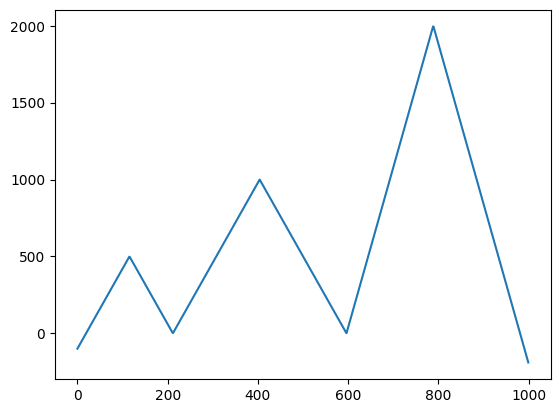

In [28]:
plt.plot(sample_fitness)

In [29]:
def relative_fitness_function(individuals):
    fitness0 = inner_fitness_function(individuals[0])
    fitness1 = inner_fitness_function(individuals[1])

    if fitness0 > fitness1:
        return [1,0]
    else:
        return [0,1]

In [30]:
from typing import Dict

from numpy import ndarray
from evolvepy.evaluator import ShufflePopulation

In [31]:
from evolvepy.evaluator import MultipleEvaluation

func_evaluator = FunctionEvaluator(relative_fitness_function, individual_per_call=2, mode=FunctionEvaluator.PYTHON)
evaluator = ShufflePopulation(func_evaluator)
evaluator = MultipleEvaluation(evaluator, 3, agregator=np.sum)

In [32]:
from evolvepy.generator.mutation import NumericMutationLayer, sum_mutation
from evolvepy.generator.crossover import one_point
from evolvepy.generator.selection import tournament

In [33]:
from evolvepy.generator import Generator, CombineLayer, Concatenate, Layer, FilterFirsts, ElitismLayer

# Defines the layers of the generator
first_layer = Layer() # Input layer 

# First path: Combine -> Mutation -> Filter
combine = CombineLayer(tournament, one_point)
mutation = NumericMutationLayer(sum_mutation, 1.0, 0.0, (-10.0, 10.0))
filter1 = FilterFirsts(95)
first_layer.next = combine
combine.next = mutation
mutation.next = filter1

# Second path: Sort -> Filter
elitism = ElitismLayer(5)
first_layer.next = elitism

# Combine both paths
concatenate = Concatenate()
filter1.next = concatenate
elitism.next = concatenate

# Creates the generator, specifying that an individual has only one chromosome, which can vary between -1000 and 4000 
generator = Generator(descriptor = descriptor, first_layer=first_layer, last_layer=concatenate)

In [34]:


from evolvepy.callbacks import MemoryStoreLogger
from evolvepy.callbacks import DynamicMutation

from evolvepy import Evolver



memory_logger = MemoryStoreLogger(log_population=True)

# Creates the DynamicMutation callback
dyn_mut = DynamicMutation([mutation.name], # Target mutation layers
                patience=3, refinement_patience=3, exploration_patience=10, # How many generations without improvements wait before realizing it got stuck in each stage
                refinement_steps=2, exploration_steps=3, # How many refinement or exploration steps to do
                refinement_divider=2, exploration_multiplier=4, # By how much to divide/multiply
                use_genes=False, threshould=0) 



# Here we specify for Evolver to use the generator and evaluator, in generations of 100 individuals.
evolver = Evolver(generator, evaluator, 100, callbacks=[memory_logger, dyn_mut])

In [35]:
hist, last_population = evolver.evolve(200) 


In [36]:
population_hist = []

for log in memory_logger.log:
    population_hist.append(log["population"]["chr0"][:,0])

population_hist = np.array(population_hist)

In [37]:
real_fitness_hist = np.empty_like(population_hist)

for i in range(population_hist.shape[0]):
    for j in range(population_hist.shape[1]):
        real_fitness_hist[i,j] = inner_fitness_function(population_hist[i,j])

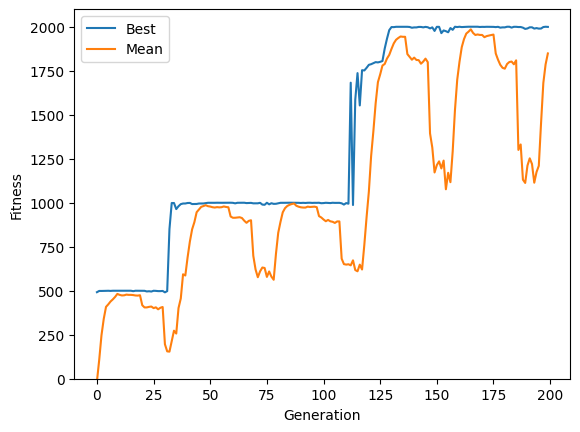

In [38]:
plt.plot(real_fitness_hist.max(axis=1))
plt.plot(real_fitness_hist.mean(axis=1))

plt.legend(["Best", "Mean"])
plt.xlabel("Generation")
plt.ylabel("Fitness")

plt.ylim(0, 2100)

plt.show()

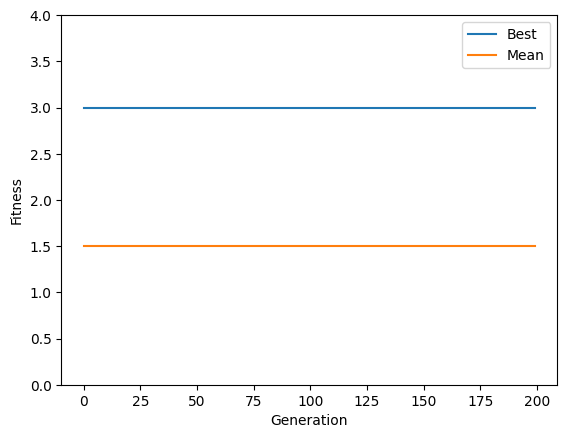

In [39]:
plt.plot(hist.max(axis=1))
plt.plot(hist.mean(axis=1))

plt.legend(["Best", "Mean"])
plt.xlabel("Generation")
plt.ylabel("Fitness")

plt.ylim(0, hist.max()+1)

plt.show()

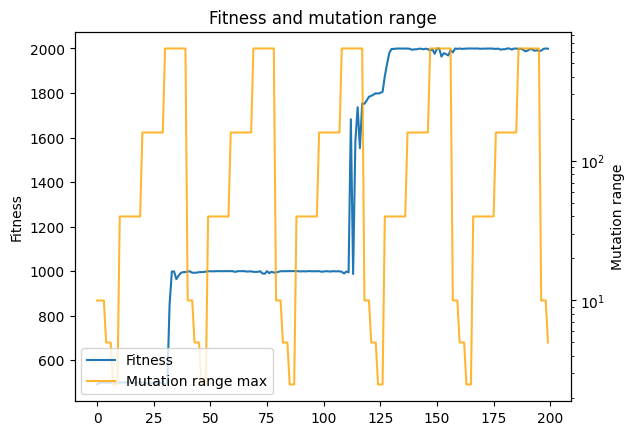

In [40]:
mutation_range_max = []

for log in memory_logger.log:
    mutation_range_max.append(log["generator"][mutation.name+"/mutation_range_max"])

fig = plt.figure()
ax = fig.add_subplot(111)
ax2 = ax.twinx()

h1 = ax.plot(real_fitness_hist.max(axis=1), label="Fitness")[0]
ax.set_ylabel("Fitness")

h2 = ax2.plot(mutation_range_max, color="orange", label="Mutation range max", alpha=0.8)[0]
ax2.set_yscale("log")
ax2.set_ylabel("Mutation range")

plt.title("Fitness and mutation range")
plt.xlabel("Generation")
plt.legend(handles=[h1, h2])
plt.show()

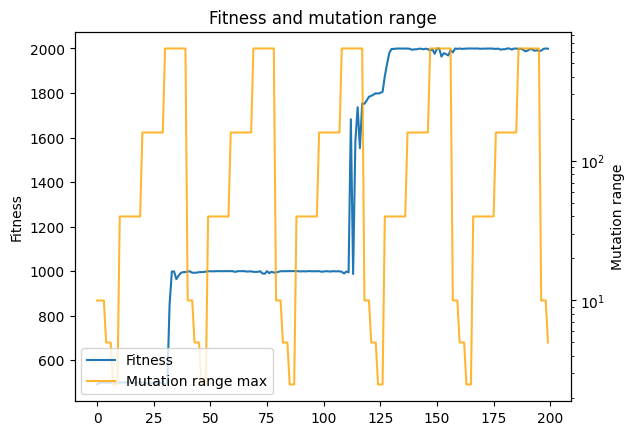

In [41]:
mutation_range_max = []

for log in memory_logger.log:
    mutation_range_max.append(log["generator"][mutation.name+"/mutation_range_max"])

fig = plt.figure()
ax = fig.add_subplot(111)
ax2 = ax.twinx()

h1 = ax.plot(real_fitness_hist.max(axis=1), label="Fitness")[0]
ax.set_ylabel("Fitness")

h2 = ax2.plot(mutation_range_max, color="orange", label="Mutation range max", alpha=0.8)[0]
ax2.set_yscale("log")
ax2.set_ylabel("Mutation range")

plt.title("Fitness and mutation range")
plt.xlabel("Generation")
plt.legend(handles=[h1, h2])
plt.show()

# Testes - Mutação dinâmica

In [42]:
dtype = [("chr0", np.float32), ("chr1", np.float32, 2)]
dtype = np.dtype(dtype)

In [43]:
x = np.zeros(2, dtype)

x[0]["chr0"]=2
#x[0]["chr1"][0]=2


In [44]:
chr_names = x.dtype.names

change = False
threshould = 1

for chr_name in  chr_names:
    if np.linalg.norm(x[0][chr_name] - x[1][chr_name]) > threshould:
        change = True

print(change)

True
